# Mapping calibrated signals to positions

A two-parameter sigmoid can turn a score into an estimated probability:

$$
q(f)=\frac{1}{1+\exp(Af+B)}.
$$

Here, $f$ is the original score, $q(f)$ is the calibrated probability of the positive outcome, and $A$ and $B$ set the slope and location of the sigmoid. The two values are estimated on observations that were not used to fit the original prediction rule.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import math
import sys
import time
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_sp500')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH)
raw['observation_date'] = pd.to_datetime(raw['observation_date'])
prices = raw.set_index('observation_date')['SP500'].dropna().astype(float).sort_index()
simple_returns = prices.pct_change()
log_returns = np.log(prices).diff()
FIGURES = ROOT / 'outputs' / 'figures' / '22_position_sizing'
TABLES = ROOT / 'outputs' / 'tables' / '22_position_sizing'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)
data_provenance = pd.DataFrame({'Field': ['Series', 'Provider', 'Source', 'Retrieved', 'First price', 'Last price', 'Price observations'], 'Value': ['S&P 500', 'Federal Reserve Bank of St. Louis', DATA_URL, '2026-09-28', str(prices.index.min().date()), str(prices.index.max().date()), len(prices)]})
from sklearn.linear_model import LogisticRegression
from RiskLabAI.backtest.advanced_bet_sizing import PlattCalibrator, distributionally_robust_kelly_fraction, expected_calibration_error, kelly_bet_fraction
from RiskLabAI.backtest.bet_sizing import average_bet_sizes, avg_active_signals, bet_size_sigmoid, compute_sigmoid_width, discrete_signal, generate_signal, inverse_price, limit_price, probability_bet_size, strategy_bet_sizing, target_position
feature_frame = pd.DataFrame({'Five-day return': np.log(prices).diff(5), 'Twenty-day return': np.log(prices).diff(20), 'Twenty-day variation': log_returns.rolling(20).std(), 'Distance from sixty-day mean': np.log(prices) - np.log(prices).rolling(60).mean()})
outcome = (log_returns.shift(-1) > 0).astype(int).rename('Positive next day')
model_data = feature_frame.join(outcome).dropna()
train_end = int(0.6 * len(model_data))
calibration_end = int(0.8 * len(model_data))
train = model_data.iloc[:train_end]
calibration = model_data.iloc[train_end:calibration_end]
test = model_data.iloc[calibration_end:]
feature_names = list(feature_frame.columns)
base_model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000)
base_model.fit(train[feature_names], train['Positive next day'])
validation_probabilities = base_model.predict_proba(calibration[feature_names])[:, 1]
test_probabilities = base_model.predict_proba(test[feature_names])[:, 1]
validation_outcomes = calibration['Positive next day'].to_numpy()
test_outcomes = test['Positive next day'].to_numpy()

def stretch_probabilities(probabilities, multiplier):
    clipped = np.clip(np.asarray(probabilities, dtype=float), 1e-06, 1 - 1e-06)
    logits = np.log(clipped / (1.0 - clipped))
    return 1.0 / (1.0 + np.exp(-multiplier * logits))
distortion = 12.0
distorted_validation = stretch_probabilities(validation_probabilities, distortion)
distorted_test = stretch_probabilities(test_probabilities, distortion)
raw_calibrator = PlattCalibrator().fit(validation_probabilities, validation_outcomes)
distortion_calibrator = PlattCalibrator().fit(distorted_validation, validation_outcomes)
calibrated_test = raw_calibrator.transform(test_probabilities)
repaired_test = distortion_calibrator.transform(distorted_test)

def brier_score(probabilities, outcomes):
    return float(np.mean((np.asarray(probabilities) - np.asarray(outcomes)) ** 2))

def calibration_bins(probabilities, outcomes, name, n_bins=10):
    frame = pd.DataFrame({'Probability': probabilities, 'Outcome': outcomes})
    frame['Band'] = pd.cut(frame['Probability'], bins=np.linspace(0, 1, n_bins + 1), include_lowest=True)
    grouped = frame.groupby('Band', observed=True).agg(**{'Observations': ('Outcome', 'size'), 'Average probability': ('Probability', 'mean'), 'Observed frequency': ('Outcome', 'mean')}).reset_index()
    grouped.insert(0, 'Method', name)
    grouped['Band'] = grouped['Band'].astype(str)
    return grouped
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Probability Study

Calibration error and squared probability error summarize two different aspects of a probability forecast:

$$
ECE=\sum_{j=1}^{J}\frac{n_j}{T}\left|\overline y_j-\overline q_j\right|,
\qquad
BS=\frac{1}{T}\sum_{t=1}^{T}(q_t-y_t)^2.
$$

Here, $J$ is the number of probability bands, $n_j$ is the number of observations in band $j$, $T$ is the test-sample size, $\overline y_j$ is the observed positive frequency in the band, $\overline q_j$ is its average forecast probability, $q_t$ is forecast $t$, $y_t$ is its zero-one outcome, $ECE$ is expected calibration error, and $BS$ is the Brier score.

,Field,Value
0,Series,S&P 500
1,Provider,Federal Reserve Bank of St. Louis
2,Source,https://fred.stlouisfed.org/graph/fredgraph.cs...
3,Retrieved,2026-09-28
4,First price,2016-09-26
5,Last price,2025-12-31
6,Price observations,2330


,Block,First date,Last date,Observations,Positive share
0,Training,2016-12-19,2022-05-17,1362,0.555800
1,Calibration,2022-05-18,2024-03-08,454,0.508811
2,Test,2024-03-11,2025-12-31,455,0.571429


,Method,Brier score,Calibration error,Mean probability,Smallest probability,Largest probability
0,Original,0.250056,0.071728,0.499701,0.489053,0.520017
1,Platt on original,0.248819,0.062618,0.508811,0.508807,0.508813
2,Known overconfidence,0.252346,0.078174,0.496284,0.371563,0.723387
3,Platt after overconfidence,0.248798,0.062437,0.508992,0.502254,0.512521


,Method,Band,Observations,Average probability,Observed frequency
0,Original,"(0.4, 0.5]",294,0.497706,0.568027
1,Original,"(0.5, 0.6]",161,0.503343,0.577640
2,Known overconfidence,"(0.3, 0.4]",5,0.388233,0.800000
3,Known overconfidence,"(0.4, 0.5]",289,0.474019,0.564014
4,Known overconfidence,"(0.5, 0.6]",149,0.531459,0.577181
5,Known overconfidence,"(0.6, 0.7]",10,0.626008,0.600000
6,Known overconfidence,"(0.7, 0.8]",2,0.714567,0.500000
7,Repaired overconfidence,"(0.5, 0.6]",455,0.508992,0.571429


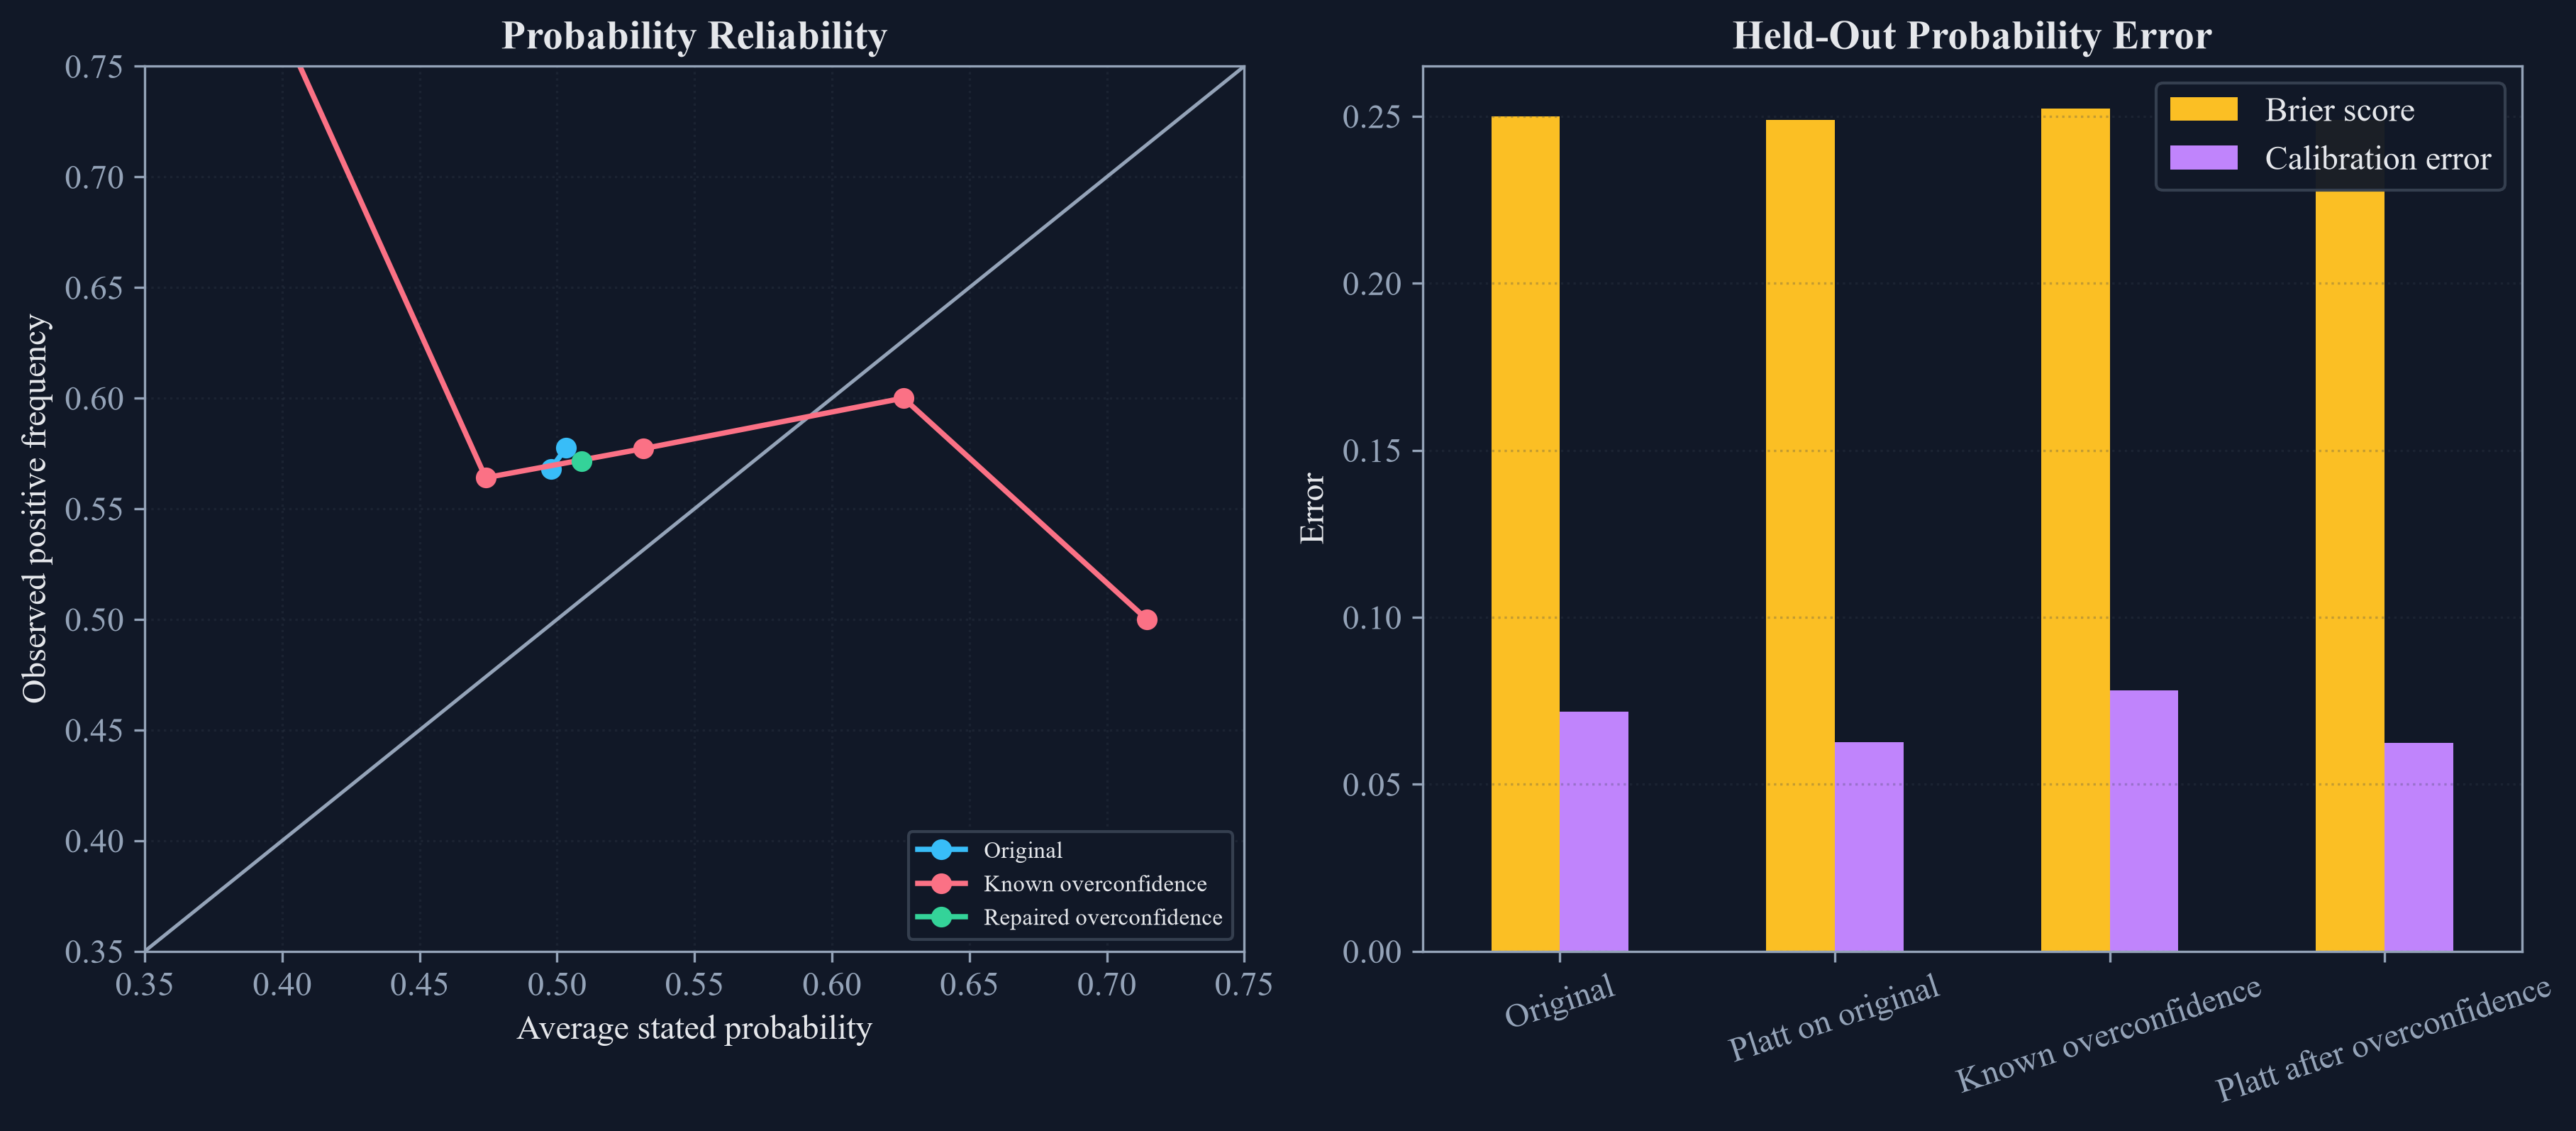

In [2]:
split_summary = pd.DataFrame({
    "Block": ["Training", "Calibration", "Test"],
    "First date": [str(train.index.min().date()), str(calibration.index.min().date()), str(test.index.min().date())],
    "Last date": [str(train.index.max().date()), str(calibration.index.max().date()), str(test.index.max().date())],
    "Observations": [len(train), len(calibration), len(test)],
    "Positive share": [train["Positive next day"].mean(), calibration["Positive next day"].mean(), test["Positive next day"].mean()],
})
probability_sets = {
    "Original": test_probabilities,
    "Platt on original": calibrated_test,
    "Known overconfidence": distorted_test,
    "Platt after overconfidence": repaired_test,
}
calibration_summary = pd.DataFrame([
    {
        "Method": name,
        "Brier score": brier_score(values, test_outcomes),
        "Calibration error": expected_calibration_error(values, test_outcomes, n_bins=10),
        "Mean probability": np.mean(values),
        "Smallest probability": np.min(values),
        "Largest probability": np.max(values),
    }
    for name, values in probability_sets.items()
])
public_calibration_bins = pd.concat([
    calibration_bins(test_probabilities, test_outcomes, "Original"),
    calibration_bins(distorted_test, test_outcomes, "Known overconfidence"),
    calibration_bins(repaired_test, test_outcomes, "Repaired overconfidence"),
], ignore_index=True)
save_table(data_provenance, "calibration_data_provenance", "Public observations used for the Chapter 19 probability study.", "tab:chapter19-calibration-data")
save_table(split_summary, "calibration_split_summary", "Time-ordered training, calibration, and test blocks.", "tab:chapter19-calibration-splits")
save_table(calibration_summary, "public_calibration_summary", "Out-of-sample probability errors before and after sigmoid calibration.", "tab:chapter19-calibration-summary")
save_table(public_calibration_bins, "public_calibration_bins", "Probability bands and observed frequencies in the public test block.", "tab:chapter19-calibration-bins")
display(data_provenance)
display(split_summary)
display(calibration_summary)
display(public_calibration_bins)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.2), constrained_layout=True)
axes[0].plot([0, 1], [0, 1], color=palette["muted"], linewidth=1.2)
for name, color in [("Original", palette["cyan"]), ("Known overconfidence", palette["rose"]), ("Repaired overconfidence", palette["green"])]:
    subset = public_calibration_bins[public_calibration_bins["Method"] == name]
    axes[0].plot(subset["Average probability"], subset["Observed frequency"], marker="o", linewidth=1.8, color=color, label=name)
axes[0].set_xlim(0.35, 0.75)
axes[0].set_ylim(0.35, 0.75)
axes[0].set_title("Probability Reliability")
axes[0].set_xlabel("Average stated probability")
axes[0].set_ylabel("Observed positive frequency")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.28)
metric_plot = calibration_summary.set_index("Method")[["Brier score", "Calibration error"]]
metric_plot.plot(kind="bar", ax=axes[1], color=[palette["amber"], palette["violet"]])
axes[1].set_title("Held-Out Probability Error")
axes[1].set_xlabel("")
axes[1].set_ylabel("Error")
axes[1].tick_params(axis="x", rotation=18)
axes[1].grid(axis="y", alpha=0.28)
save_figure(figure, "calibration_reliability")

## Probability to Signed Size

A class probability is first compared with equal odds and then mapped to a signed size:

$$
z(p,K)=\frac{p-K^{-1}}{\sqrt{p(1-p)}},
\qquad
m=s\left[2\Phi\!\left(z(p,K)\right)-1\right].
$$

Here, $p$ is the probability assigned to the predicted class, $K$ is the number of classes, $z(p,K)$ is its standardized distance from equal odds, $s\in\{-1,1\}$ is the predicted side, $\Phi$ is the standard normal distribution function, and $m\in[-1,1]$ is the signed position size.

,Predicted-class probability,Standardized score,Long size,Short size,Long size at 0.1 steps
0,0.50,0,0,0,0
1,0.52,0.040032,0.031932,-0.031932,0
2,0.55,0.100504,0.080056,-0.080056,0.1
3,0.60,0.204124,0.161744,-0.161744,0.2
4,0.70,0.436436,0.337479,-0.337479,0.3
5,0.80,0.750000,0.546745,-0.546745,0.5
6,0.90,1.333333,0.817578,-0.817578,0.8
7,0.99,4.924685,0.999999,-0.999999,1


,Quantity,Value
0,Test observations,455
1,Long directions,161
2,Short directions,294
3,Mean absolute size,0.004253
4,Largest absolute size,0.031959
5,Mean confidence,0.502665


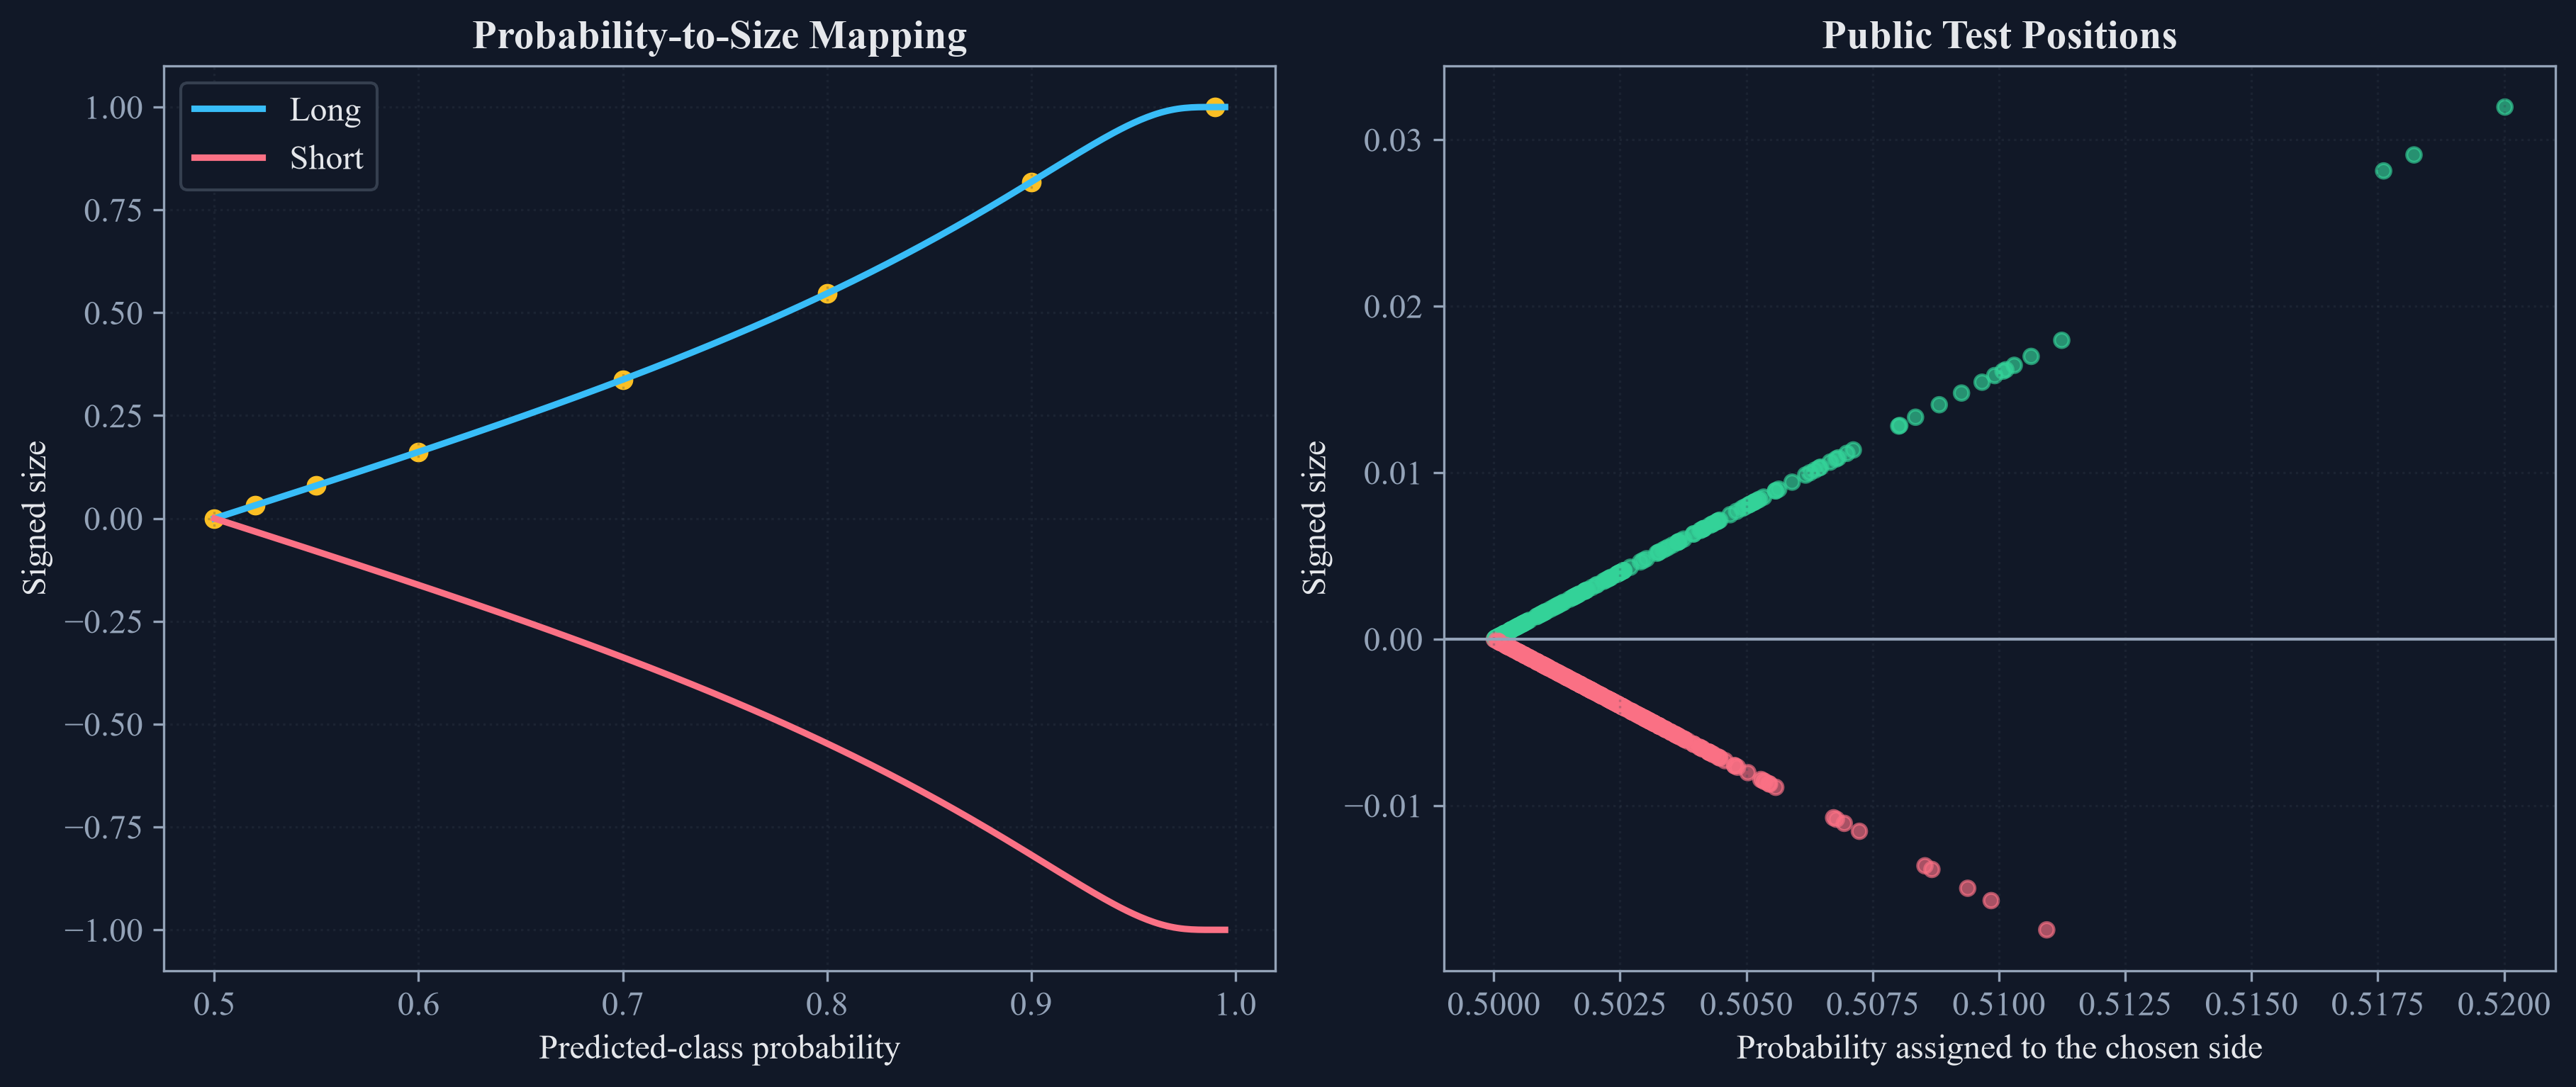

In [3]:
probability_grid = np.array([0.50, 0.52, 0.55, 0.60, 0.70, 0.80, 0.90, 0.99])
score_grid = (probability_grid - 0.5) / np.sqrt(probability_grid * (1.0 - probability_grid))
positive_sizes = probability_bet_size(score_grid, np.ones_like(score_grid))
size_mapping = pd.DataFrame({
    "Predicted-class probability": probability_grid,
    "Standardized score": score_grid,
    "Long size": positive_sizes,
    "Short size": -positive_sizes,
    "Long size at 0.1 steps": discrete_signal(pd.Series(positive_sizes), 0.1).to_numpy(),
})
test_sides = np.where(test_probabilities >= 0.5, 1, -1)
test_confidence = np.where(test_sides == 1, test_probabilities, 1.0 - test_probabilities)
test_scores = (test_confidence - 0.5) / np.sqrt(test_confidence * (1.0 - test_confidence))
test_sizes = probability_bet_size(test_scores, test_sides)
public_size_summary = pd.DataFrame({
    "Quantity": ["Test observations", "Long directions", "Short directions", "Mean absolute size", "Largest absolute size", "Mean confidence"],
    "Value": [len(test_sizes), int(np.sum(test_sides == 1)), int(np.sum(test_sides == -1)), np.mean(np.abs(test_sizes)), np.max(np.abs(test_sizes)), np.mean(test_confidence)],
})
save_table(size_mapping, "probability_size_mapping", "Probability-to-size mapping for a two-class decision.", "tab:chapter19-probability-size")
save_table(public_size_summary, "public_size_summary", "Position-size summary for the public test block.", "tab:chapter19-public-size-summary")
display(size_mapping)
display(public_size_summary)

dense_probabilities = np.linspace(0.5, 0.995, 300)
dense_scores = (dense_probabilities - 0.5) / np.sqrt(dense_probabilities * (1.0 - dense_probabilities))
dense_sizes = probability_bet_size(dense_scores, np.ones_like(dense_scores))
figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
axes[0].plot(dense_probabilities, dense_sizes, color=palette["cyan"], linewidth=2.2, label="Long")
axes[0].plot(dense_probabilities, -dense_sizes, color=palette["rose"], linewidth=2.2, label="Short")
axes[0].scatter(probability_grid, positive_sizes, color=palette["amber"], s=32)
axes[0].set_title("Probability-to-Size Mapping")
axes[0].set_xlabel("Predicted-class probability")
axes[0].set_ylabel("Signed size")
axes[0].legend()
axes[0].grid(alpha=0.28)
axes[1].scatter(test_confidence, test_sizes, c=np.where(test_sides > 0, palette["green"], palette["rose"]), alpha=0.65, s=24)
axes[1].axhline(0, color=palette["muted"], linewidth=1.0)
axes[1].set_title("Public Test Positions")
axes[1].set_xlabel("Probability assigned to the chosen side")
axes[1].set_ylabel("Signed size")
axes[1].grid(alpha=0.28)
save_figure(figure, "probability_size_map")

## Aggregating concurrent discrete signals

Overlapping positions are averaged and then placed on a declared size grid:

$$
\overline m_t=\frac{1}{|A_t|}\sum_{i\in A_t}m_i,
\qquad
m_t^{(d)}=\operatorname{clip}_{[-1,1]}\!\left(d\,\operatorname{round}\!\left(\frac{\overline m_t}{d}\right)\right).
$$

Here, $A_t$ is the set of positions active at time $t$, $|A_t|$ is its size, $m_i$ is the signed size of active position $i$, $\overline m_t$ is their average, $d\in(0,1]$ is the size step, and $m_t^{(d)}$ is the bounded discrete position.

,Date,Average active size,Discrete active size,Active positions
0,2024-03-11,-0.000477,0,1
1,2024-04-02,-0.000262,0,2
2,2024-04-09,-0.000047,0,1
3,2024-04-23,0.001737,0,2
4,2024-04-30,0.003520,0,1
...,...,...,...,...
56,2025-11-18,-0.003188,0,1
57,2025-12-03,-0.002413,0,2
58,2025-12-10,-0.001639,0,1
59,2025-12-24,-0.003545,0,2


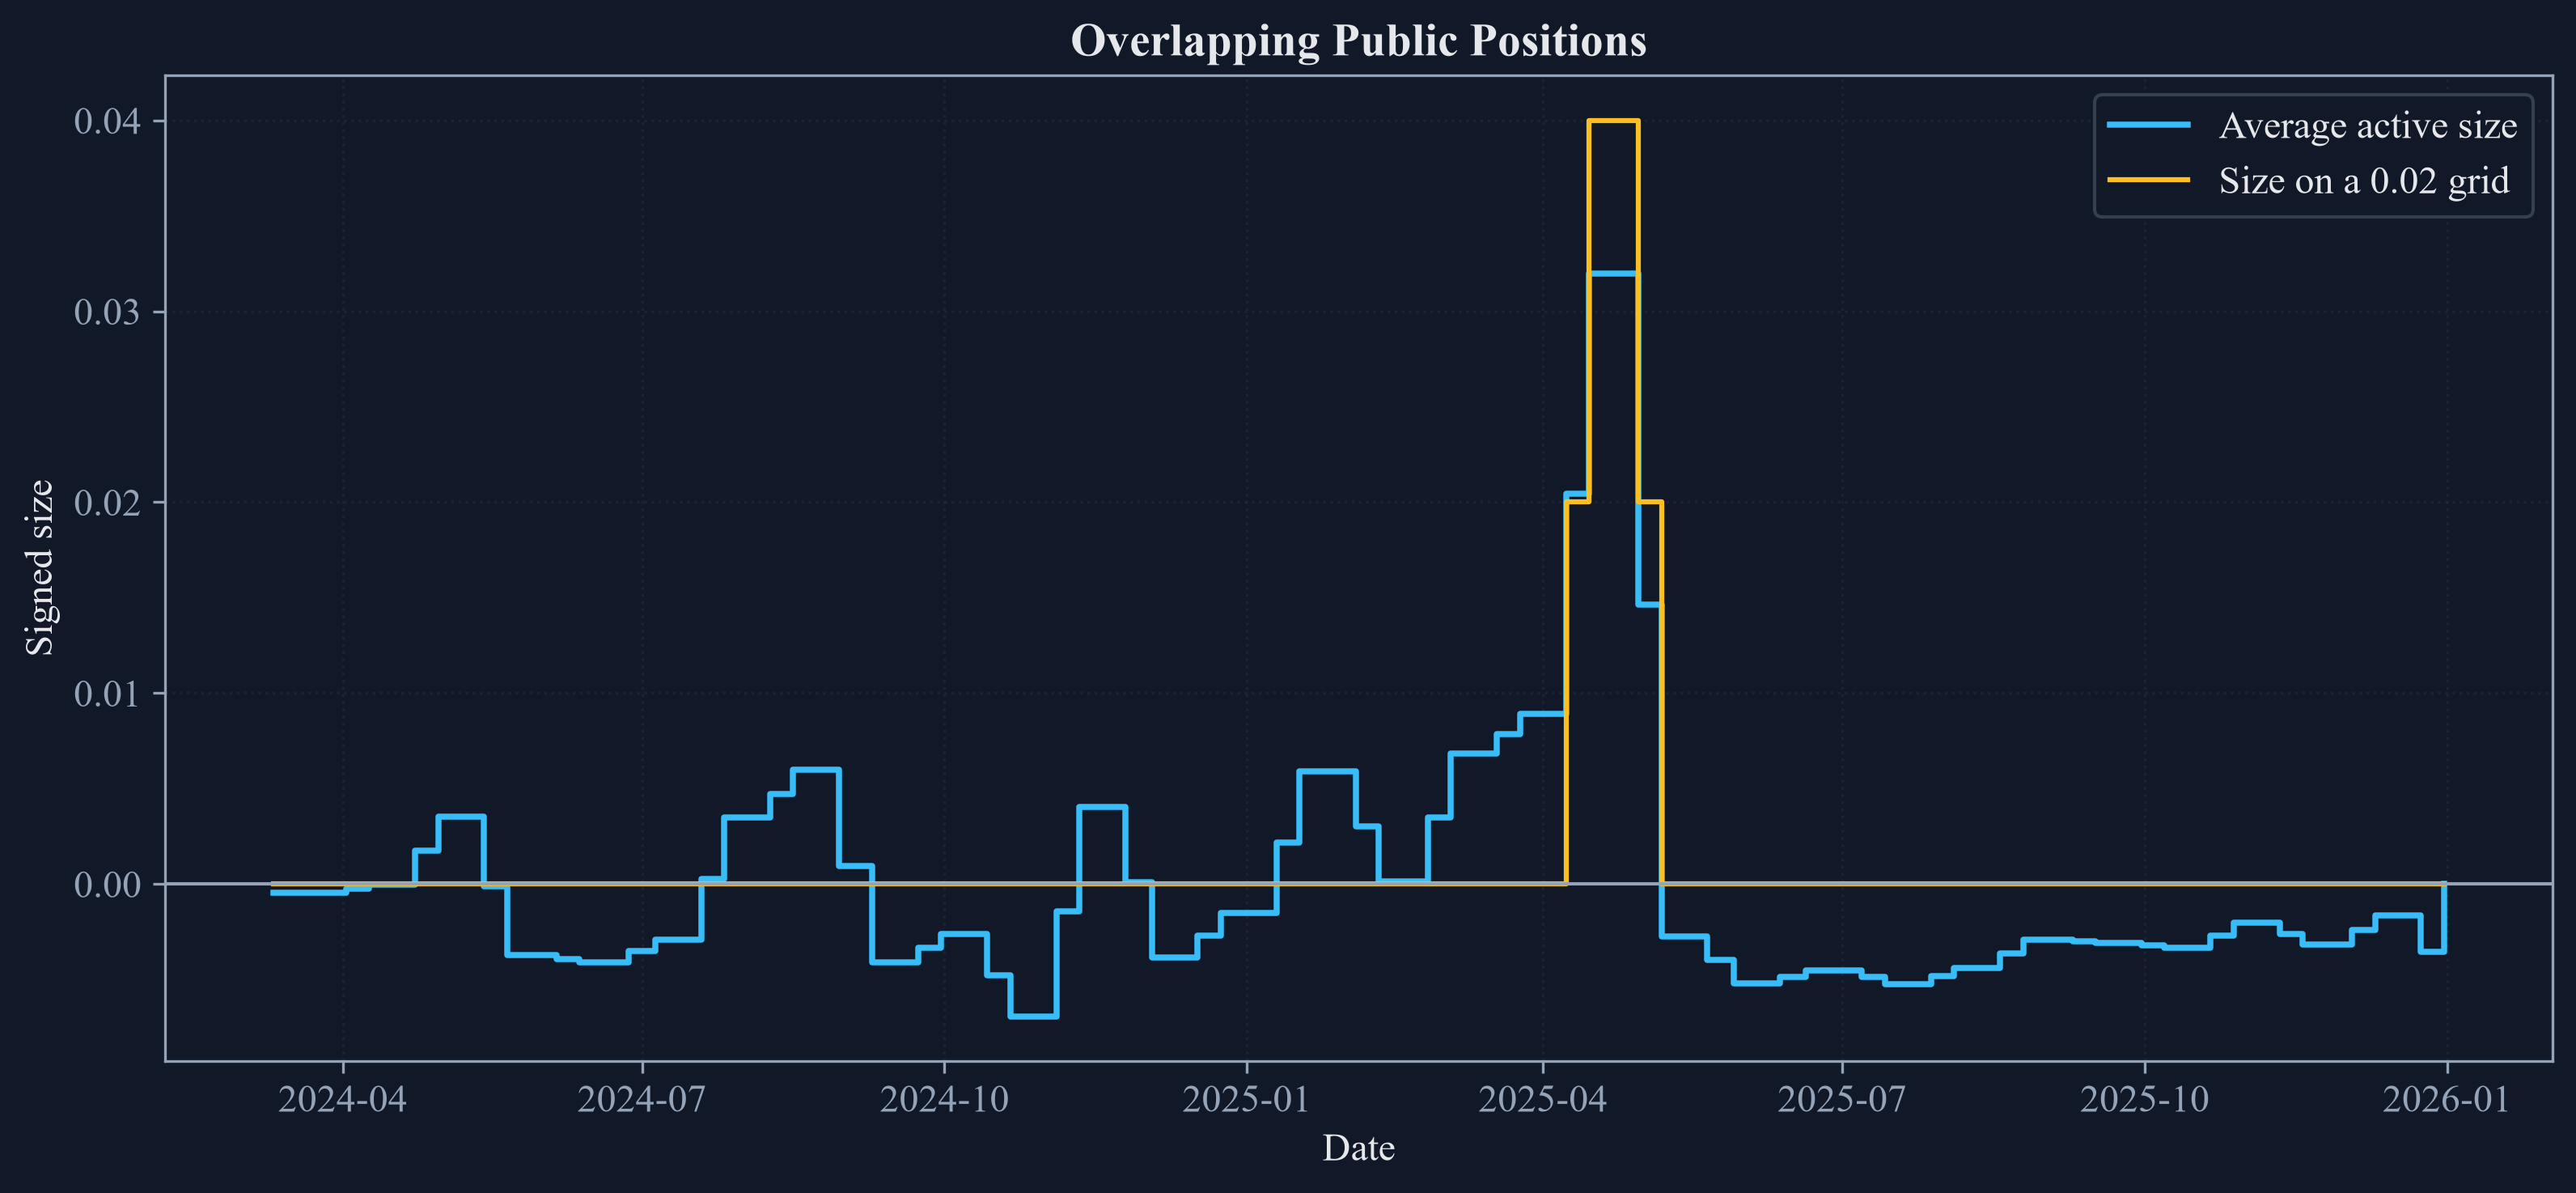

In [4]:
selected_locations = np.arange(0, len(test), 15)
event_starts = test.index[selected_locations]
end_locations = np.minimum(selected_locations + 20, len(test) - 1)
event_ends = test.index[end_locations]
event_probabilities = pd.Series(test_confidence[selected_locations], index=event_starts)
event_predictions = pd.Series(test_sides[selected_locations], index=event_starts)
events = pd.DataFrame({"t1": event_ends}, index=event_starts)
event_scores = (event_probabilities - 0.5) / np.sqrt(event_probabilities * (1.0 - event_probabilities))
individual_signals = event_predictions * (2.0 * ss.norm.cdf(event_scores) - 1.0)
signal_frame = individual_signals.rename("signal").to_frame().join(events)
active_average = avg_active_signals(signal_frame, n_threads=1).sort_index()
discrete_active = discrete_signal(active_average, step_size=0.02)
generated_active = generate_signal(events, 0.02, event_probabilities, event_predictions, 2, 1).sort_index()
active_signal_table = pd.DataFrame({
    "Date": active_average.index.strftime("%Y-%m-%d"),
    "Average active size": active_average.to_numpy(),
    "Discrete active size": discrete_active.to_numpy(),
    "Active positions": [int(((event_starts <= date) & (date < event_ends)).sum()) for date in active_average.index],
})
save_table(active_signal_table, "active_signal_table", "Average and discrete sizes as public-data positions overlap.", "tab:chapter19-active-signals")
display(active_signal_table)

figure, axis = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axis.step(active_average.index, active_average, where="post", color=palette["cyan"], linewidth=1.8, label="Average active size")
axis.step(discrete_active.index, discrete_active, where="post", color=palette["amber"], linewidth=1.5, label="Size on a 0.02 grid")
axis.axhline(0, color=palette["muted"], linewidth=1.0)
axis.set_title("Overlapping Public Positions")
axis.set_xlabel("Date")
axis.set_ylabel("Signed size")
axis.legend()
axis.grid(alpha=0.28)
save_figure(figure, "active_signal_path")

## Dynamic Price Mappings

A price gap can be mapped to a bounded size and an integer target position:

$$
m(w,x)=\frac{x}{\sqrt{w+x^2}},
\qquad
\widehat q=\operatorname{int}\!\left(Qm(w,f-p)\right),
\qquad
w=x_*^2\left(m_*^{-2}-1\right).
$$

Here, $x=f-p$ is the gap between forecast price $f$ and current price $p$, $w>0$ controls how quickly size approaches its bounds, $m(w,x)$ is the continuous size, $Q$ is the largest absolute position, $\widehat q$ is the integer target position, and the chosen pair $(x_*,m_*)$ calibrates $w$.

,Market price,Forecast price,Price gap,Continuous size,Target position,Average limit price
0,95,115,20,0.986763,98,112.227449
1,100,115,15,0.976824,97,112.365739
2,105,115,10,0.950000,95,112.566952
3,110,115,5,0.835619,83,113.219100
4,115,115,0,0,0,115
5,120,115,-5,-0.835619,-83,113.219100
6,125,115,-10,-0.950000,-95,112.566952
7,130,115,-15,-0.976824,-97,112.365739
8,135,115,-20,-0.986763,-98,112.227449


,Quantity,Value
0,Calibration gap,10
1,Calibration size,0.950000
2,Width,10.803324
3,Forecast price,115
4,Market price,100
5,Maximum position,100
6,Target position,97
7,Average limit price,112.365739


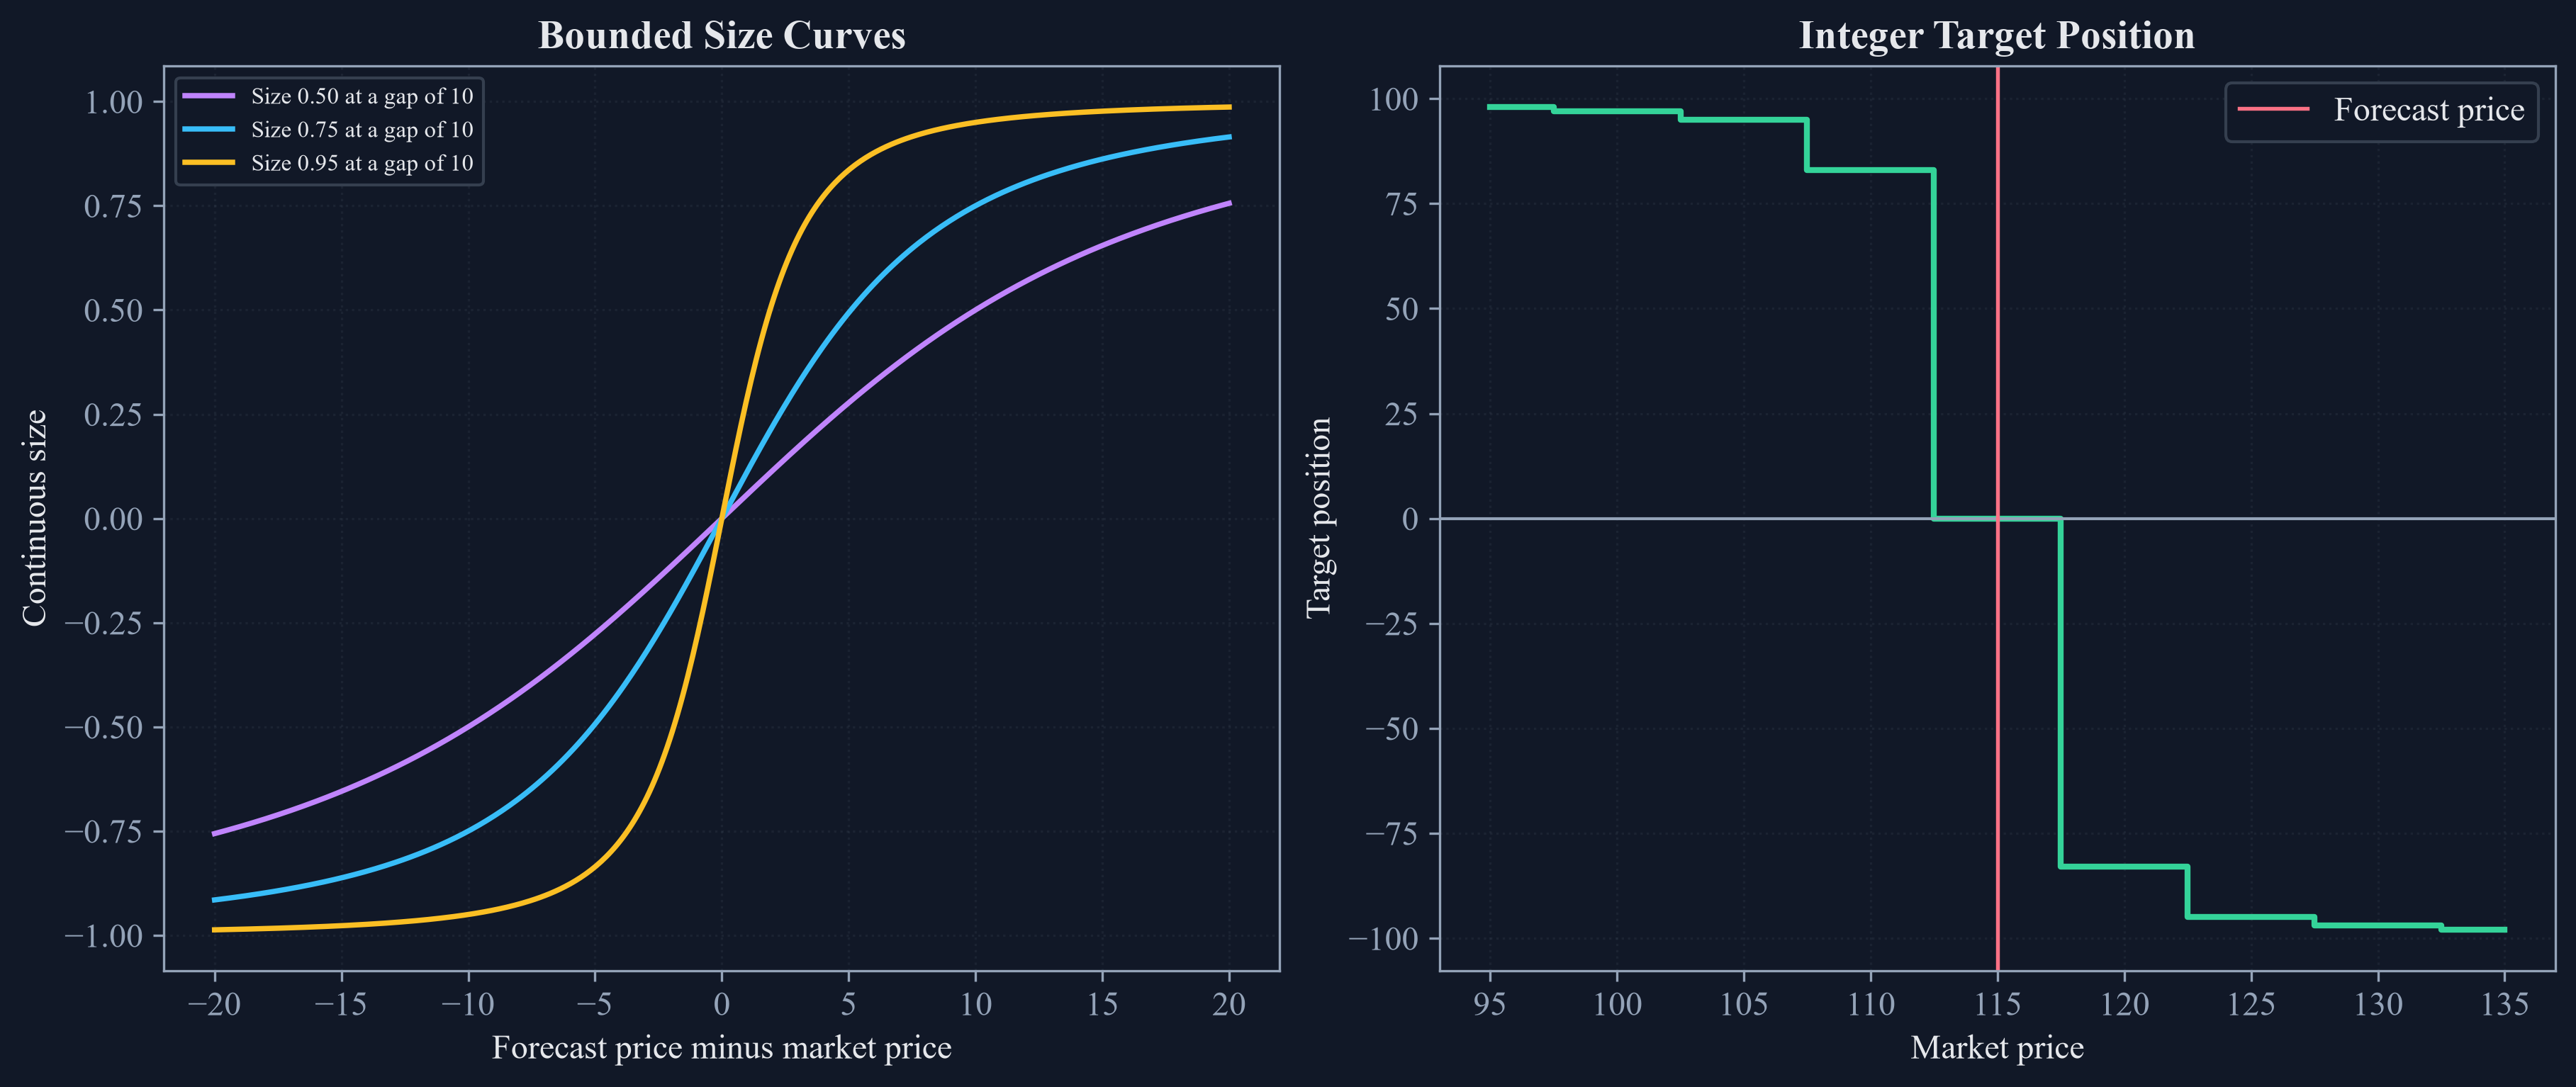

In [5]:
width = compute_sigmoid_width(10.0, 0.95)
forecast_price = 115.0
maximum_position = 100
current_position = 0
market_prices = np.array([95.0, 100.0, 105.0, 110.0, 115.0, 120.0, 125.0, 130.0, 135.0])
dynamic_rows = []
for market_price in market_prices:
    target = target_position(width, forecast_price, market_price, maximum_position)
    order_price = limit_price(target, current_position, forecast_price, width, maximum_position) if target != current_position else forecast_price
    dynamic_rows.append({"Market price": market_price, "Forecast price": forecast_price, "Price gap": forecast_price - market_price, "Continuous size": bet_size_sigmoid(width, forecast_price - market_price), "Target position": target, "Average limit price": order_price})
dynamic_position_table = pd.DataFrame(dynamic_rows)
preliminary_dynamic_reproduction = pd.DataFrame({
    "Quantity": ["Calibration gap", "Calibration size", "Width", "Forecast price", "Market price", "Maximum position", "Target position", "Average limit price"],
    "Value": [10.0, 0.95, width, 115.0, 100.0, 100, target_position(width, 115.0, 100.0, 100), limit_price(target_position(width, 115.0, 100.0, 100), 0, 115.0, width, 100)],
})
save_table(dynamic_position_table, "dynamic_position_table", "Target positions and average limit prices for a fixed forecast.", "tab:chapter19-dynamic-positions")
save_table(preliminary_dynamic_reproduction, "preliminary_dynamic_reproduction", "Reproduction of the dynamic-position numerical example.", "tab:chapter19-dynamic-reproduction", fit=False)
display(dynamic_position_table)
display(preliminary_dynamic_reproduction)

gaps = np.linspace(-20, 20, 400)
figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
for chosen_size, color in [(0.50, palette["violet"]), (0.75, palette["cyan"]), (0.95, palette["amber"])]:
    chosen_width = compute_sigmoid_width(10.0, chosen_size)
    axes[0].plot(gaps, [bet_size_sigmoid(chosen_width, gap) for gap in gaps], color=color, linewidth=1.8, label=f"Size {chosen_size:.2f} at a gap of 10")
axes[0].set_title("Bounded Size Curves")
axes[0].set_xlabel("Forecast price minus market price")
axes[0].set_ylabel("Continuous size")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.28)
axes[1].step(dynamic_position_table["Market price"], dynamic_position_table["Target position"], where="mid", color=palette["green"], linewidth=2.0)
axes[1].axhline(0, color=palette["muted"], linewidth=1.0)
axes[1].axvline(forecast_price, color=palette["rose"], linewidth=1.3, label="Forecast price")
axes[1].set_title("Integer Target Position")
axes[1].set_xlabel("Market price")
axes[1].set_ylabel("Target position")
axes[1].legend()
axes[1].grid(alpha=0.28)
save_figure(figure, "dynamic_sigmoid_positions")

## Growth Fractions under Probability Uncertainty

A binary Kelly fraction and a lower-confidence version are given by:

$$
f_K(p,b)=\operatorname{clip}_{[0,f_{\max}]}\!\left(\frac{p(b+1)-1}{b}\right),
\qquad
p_L=\widehat p-z_c\sqrt{\frac{\widehat p(1-\widehat p)}{n}},
\qquad
f_R=f_K(p_L,b).
$$

Here, $p$ is a known win probability, $b>0$ is the net win per unit lost on failure, $f_K$ is the Kelly wealth fraction, $f_{\max}$ is its upper bound, $\widehat p$ is an estimated win probability, $n$ is the number of observations behind it, $z_c$ sets the lower-confidence adjustment, $p_L$ is the pessimistic probability, and $f_R$ is the uncertainty-adjusted fraction.

,Win probability,Observations,Full Kelly fraction,Uncertainty-adjusted fraction
0,0.50,25,0,0
1,0.50,100,0,0
2,0.50,1000,0,0
3,0.50,1000000,0,0
4,0.55,25,0.1,0
5,0.55,100,0.1,0.000501
6,0.55,1000,0.1,0.068536
7,0.55,1000000,0.1,0.099005
8,0.60,25,0.2,0.004041
9,0.60,100,0.2,0.102020


,Probability quantile,Predicted-class probability,Full Kelly fraction,Uncertainty-adjusted fraction
0,10 percent,0.500367,0.000733,0
1,25 percent,0.501031,0.002062,0
2,50 percent,0.502133,0.004266,0
3,75 percent,0.503414,0.006827,0
4,90 percent,0.505249,0.010497,0


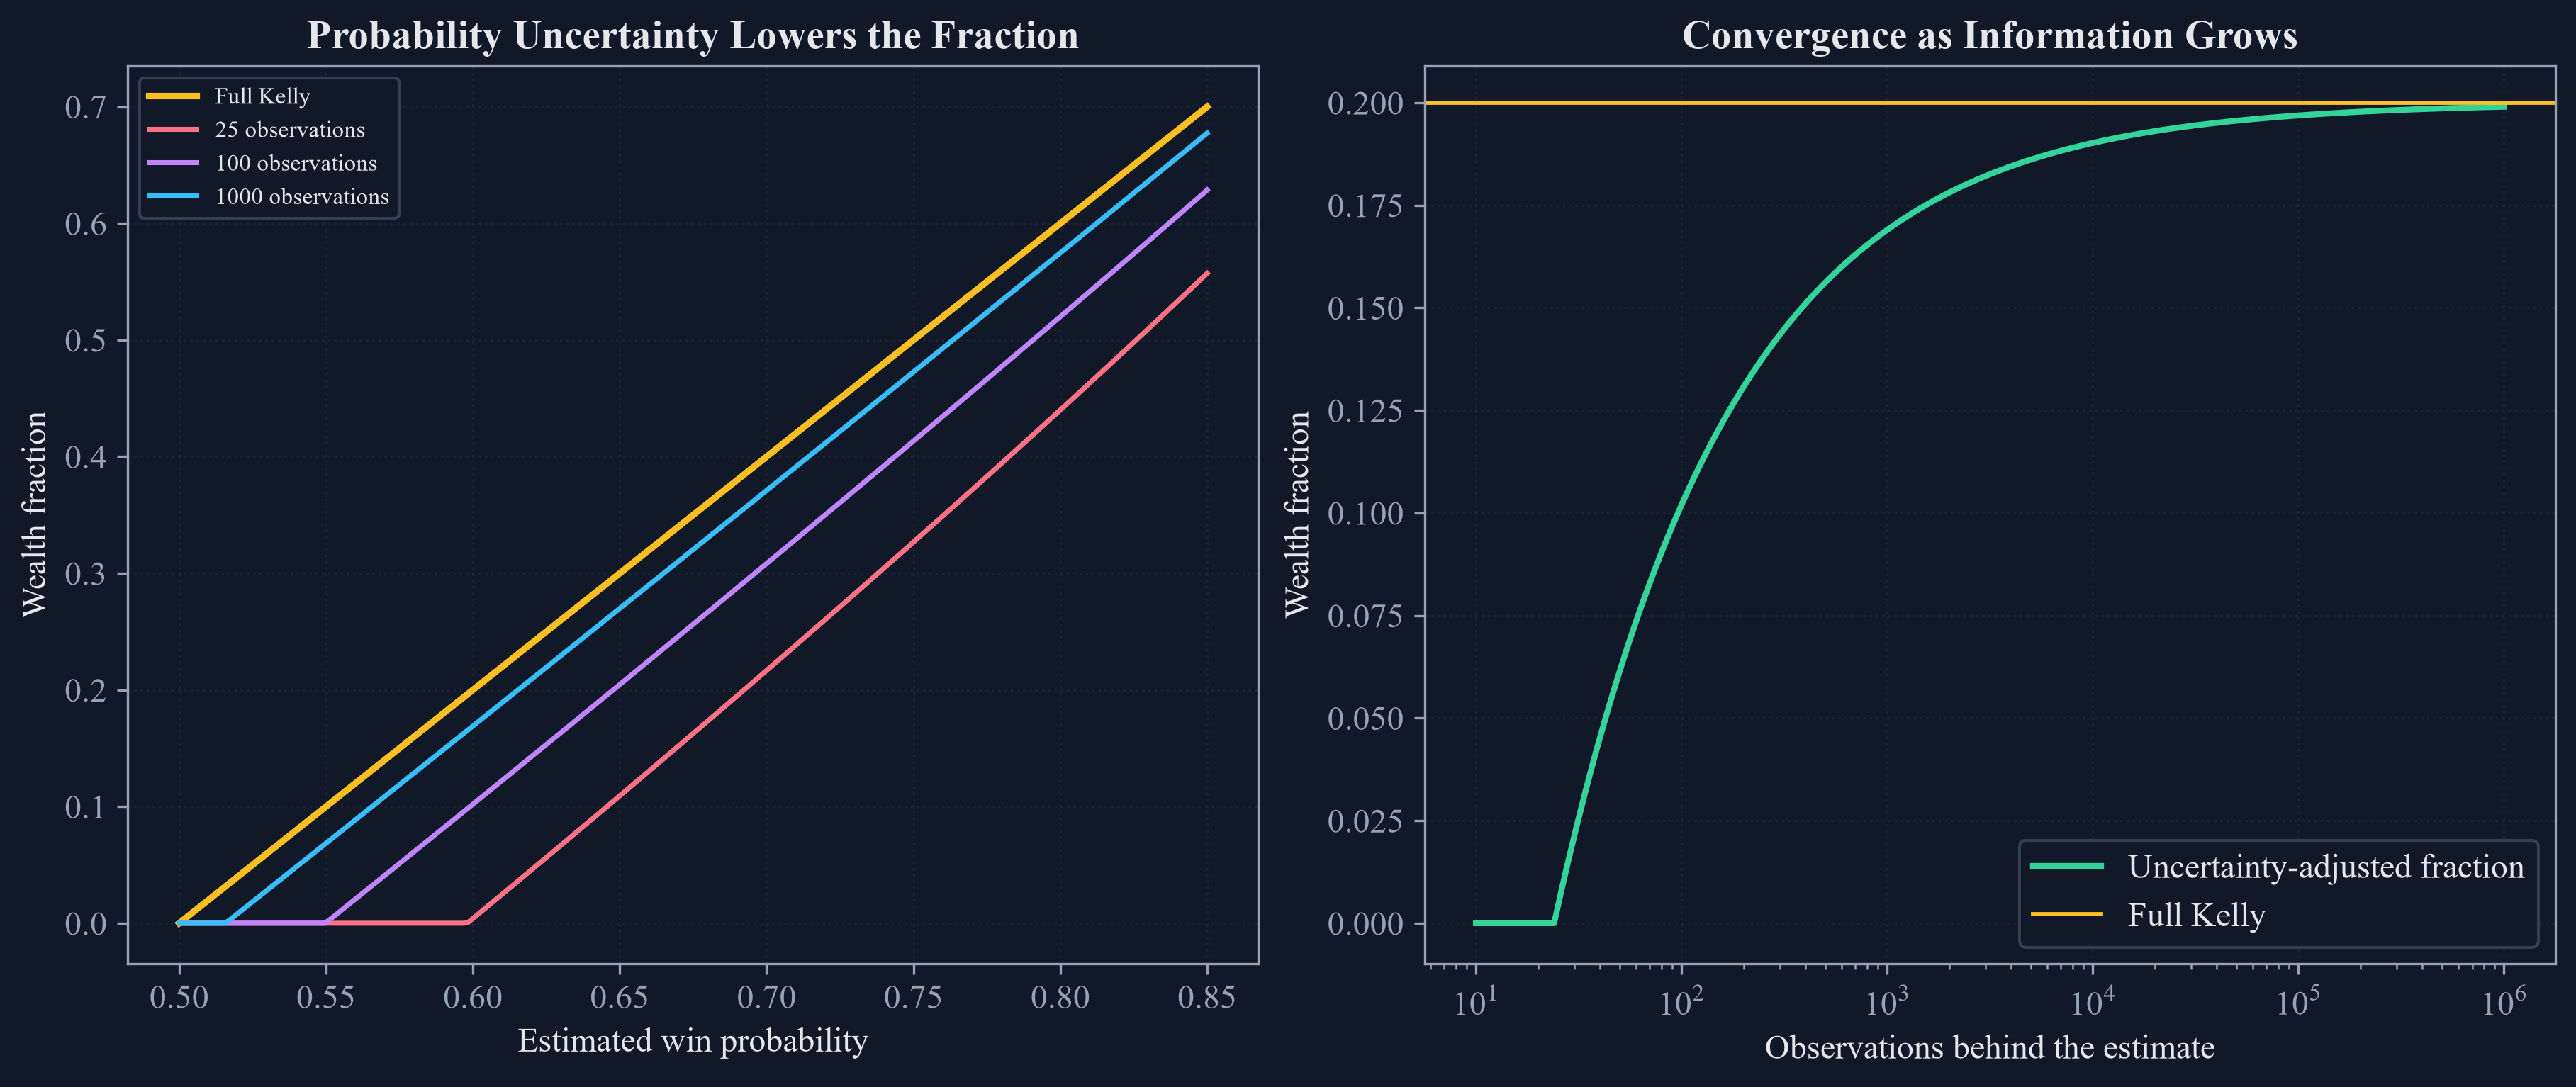

In [6]:
kelly_rows = []
for probability in [0.50, 0.55, 0.60, 0.70, 0.80]:
    for observations in [25, 100, 1000, 1000000]:
        kelly_rows.append({
            "Win probability": probability,
            "Observations": observations,
            "Full Kelly fraction": float(kelly_bet_fraction(probability, 1.0)),
            "Uncertainty-adjusted fraction": float(distributionally_robust_kelly_fraction(probability, observations, 1.0, confidence_z=1.0)),
        })
kelly_sensitivity = pd.DataFrame(kelly_rows)
public_probability_quantiles = np.quantile(test_confidence, [0.10, 0.25, 0.50, 0.75, 0.90])
public_kelly_summary = pd.DataFrame({
    "Probability quantile": ["10 percent", "25 percent", "50 percent", "75 percent", "90 percent"],
    "Predicted-class probability": public_probability_quantiles,
    "Full Kelly fraction": kelly_bet_fraction(public_probability_quantiles, 1.0),
    "Uncertainty-adjusted fraction": distributionally_robust_kelly_fraction(public_probability_quantiles, len(train), 1.0, confidence_z=1.0),
})
save_table(kelly_sensitivity, "kelly_sensitivity", "Full and uncertainty-adjusted Kelly fractions.", "tab:chapter19-kelly-sensitivity")
save_table(public_kelly_summary, "public_kelly_summary", "Kelly fractions at probability quantiles from the public test block.", "tab:chapter19-public-kelly")
display(kelly_sensitivity)
display(public_kelly_summary)

probability_axis = np.linspace(0.5, 0.85, 250)
figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
axes[0].plot(probability_axis, kelly_bet_fraction(probability_axis), color=palette["amber"], linewidth=2.2, label="Full Kelly")
for observations, color in [(25, palette["rose"]), (100, palette["violet"]), (1000, palette["cyan"])]:
    axes[0].plot(probability_axis, distributionally_robust_kelly_fraction(probability_axis, observations), color=color, linewidth=1.7, label=f"{observations} observations")
axes[0].set_title("Probability Uncertainty Lowers the Fraction")
axes[0].set_xlabel("Estimated win probability")
axes[0].set_ylabel("Wealth fraction")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.28)
fixed_probability = 0.60
observation_axis = np.unique(np.logspace(1, 6, 240).astype(int))
convergence_fractions = np.array([float(distributionally_robust_kelly_fraction(fixed_probability, int(observations))) for observations in observation_axis])
axes[1].semilogx(observation_axis, convergence_fractions, color=palette["green"], linewidth=2.0, label="Uncertainty-adjusted fraction")
axes[1].axhline(float(kelly_bet_fraction(fixed_probability)), color=palette["amber"], linewidth=1.4, label="Full Kelly")
axes[1].set_title("Convergence as Information Grows")
axes[1].set_xlabel("Observations behind the estimate")
axes[1].set_ylabel("Wealth fraction")
axes[1].legend()
axes[1].grid(alpha=0.28)
save_figure(figure, "robust_kelly_fractions")

## Tests

In [7]:
assert len(prices) == 2330
assert len(model_data) == 2271
assert [len(train), len(calibration), len(test)] == [1362, 454, 455]
assert calibration_summary.shape == (4, 6)
assert brier_score(repaired_test, test_outcomes) < brier_score(distorted_test, test_outcomes)
assert expected_calibration_error(repaired_test, test_outcomes, 10) < expected_calibration_error(distorted_test, test_outcomes, 10)
assert np.allclose(probability_bet_size(np.array([0.0, 0.0]), np.array([1.0, -1.0])), np.array([0.0, 0.0]))
assert np.allclose(probability_bet_size(np.array([ss.norm.ppf(0.75), ss.norm.ppf(0.75)]), np.array([1.0, -1.0])), np.array([0.5, -0.5]))
controlled_average = average_bet_sizes(np.arange(10), np.array([0, 2, 8]), np.array([5, 7, 9]), np.array([1.0, 0.5, -1.0]))
assert np.allclose(controlled_average, np.array([1.0, 1.0, 0.75, 0.75, 0.75, 0.75, 0.5, 0.5, -1.0, -1.0]))
controlled_dates = pd.date_range('2020-01-01', periods=10)
controlled_starts = pd.to_datetime(['2020-01-01', '2020-01-03', '2020-01-09'])
controlled_times = pd.Series(pd.to_datetime(['2020-01-06', '2020-01-08', '2020-01-10']), index=controlled_starts)
controlled_sides = pd.Series([1, 1, -1], index=controlled_starts)
controlled_scores = pd.Series([0.0, ss.norm.ppf(0.75), ss.norm.ppf(0.75)], index=controlled_starts)
controlled_strategy = strategy_bet_sizing(controlled_dates, controlled_times, controlled_sides, controlled_scores)
assert np.allclose(controlled_strategy.to_numpy(), np.array([0, 0, 0.25, 0.25, 0.25, 0.25, 0.5, 0.5, -0.5, -0.5]))
assert np.allclose(generated_active.to_numpy(), discrete_active.to_numpy())
assert np.isclose(bet_size_sigmoid(1.0, 0.5), 0.4472135954999579)
assert np.isclose(compute_sigmoid_width(0.5, bet_size_sigmoid(1.0, 0.5)), 1.0)
assert target_position(1.0, 10.5, 10.0, 100) == 44
assert np.isclose(width, 10.803324099723)
assert target_position(width, 115.0, 100.0, 100) == 97
assert np.isclose(limit_price(97, 0, 115.0, width, 100), 112.36573855883363)
assert np.isclose(inverse_price(115.0, width, 0.5), 113.10263340389898)
assert np.isclose(float(kelly_bet_fraction(0.6)), 0.2)
assert float(kelly_bet_fraction(0.5)) == 0.0
assert float(distributionally_robust_kelly_fraction(0.6, 40)) < float(distributionally_robust_kelly_fraction(0.6, 1000000)) <= float(kelly_bet_fraction(0.6))
assert (FIGURES / 'calibration_reliability.pdf').exists()
assert (FIGURES / 'probability_size_map.pdf').exists()
assert (FIGURES / 'active_signal_path.pdf').exists()
assert (FIGURES / 'dynamic_sigmoid_positions.pdf').exists()
assert (FIGURES / 'robust_kelly_fractions.pdf').exists()
check_summary = pd.DataFrame({'Check': ['Public file identity', 'Time-ordered split', 'Known overconfidence repaired', 'Probability-size mapping', 'Overlapping averages', 'Dynamic position inverse', 'Uncertainty-adjusted fraction'], 'Status': ['Pass'] * 7})
display(check_summary)


,Check,Status
0,Public file identity,Pass
1,Time-ordered split,Pass
2,Known overconfidence repaired,Pass
3,Probability-size mapping,Pass
4,Overlapping averages,Pass
5,Dynamic position inverse,Pass
6,Uncertainty-adjusted fraction,Pass
